# **¿LOGRARAN LLEGAR A LA CIMA DEL EVEREST?**

**Número de Grupo:** 7

**Integrantes:**
*   94696, Heiland Valentina Abril
*   95196, Pugliese Lourdes Belen
*   94822, Mendez Agustin Alberto
*   400148, de la Cuesta Luján
*   406644, Castigliano Federica
*   401156, Mamud Savina
* 403938, Bertuzzi Valentin
* 96121, Latorre Luka


# Experimentos de clasificación para predecir la cumbre del Everest

## Objetivo y criterio de decisión

Este notebook reúne los experimentos de **Regresión Logística, Random Forest y XGBoost** para predecir `summited` (`1`: alcanzó la cima; `0`: no alcanzó la cima). El objetivo no es maximizar una métrica aislada, sino analizar qué modelo ofrece una combinación defendible de precisión, capacidad de detección y control de falsos positivos.

En este problema, un **falso positivo (FP)** ocurre cuando el modelo predice que una persona alcanzará la cima, pero en realidad no lo hace. Como una expedición al Everest implica condiciones extremas y riesgos para la vida, las predicciones positivas erróneas deben penalizarse especialmente. Sin embargo, reducir FP elevando mucho el umbral puede aumentar los **falsos negativos (FN)**, es decir, no identificar ascensos que sí culminan en cumbre. Por eso se comparan conjuntamente ambas clases de error.



### Orden del análisis
1. Regresión Logística.
2. Random Forest.
3. XGBoost.
4. Comparación global, ranking y recomendación.

Las métricas se calculan sobre el mismo conjunto de test para que la comparación sea justa. Los umbrales se seleccionan/estudian con validación cuando corresponde; el conjunto de test se reserva para la evaluación final.

## 1. Carga de datos y particiones comunes

Se utiliza el CSV limpio del proyecto, con la variable objetivo `summited` y predictores numéricos (incluidas las categorías codificadas previamente). Se conserva una partición estratificada reproducible: 64 % entrenamiento, 16 % validación y 20 % test. La validación permite comparar decisiones sin ajustar repetidamente los modelos contra el test final.


In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from google.colab import drive
drive.mount('/content/drive')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)
from xgboost import XGBClassifier

pd.set_option("display.max_columns", None)

DATA_PATH = '/content/drive/MyDrive/Ciencia de Datos TP/Entrega 3/everest_dataset_limpio.csv'
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"No se encontró {DATA_PATH}. Modificá DATA_PATH para apuntar al CSV limpio."
    )

df = pd.read_csv(DATA_PATH)
if "summited" not in df.columns:
    raise ValueError("El dataset debe contener la columna objetivo 'summited'.")
df = df.dropna(subset=["summited"]).copy()
if df["summited"].isna().any() or set(df["summited"].unique()) - {0, 1}:
    raise ValueError("summited debe contener únicamente valores 0 y 1, sin faltantes.")

# XGBoost requiere predictores numéricos; la codificación categórica debe estar hecha.
X = df.drop(columns=["summited"])
y = df["summited"].astype(int)
no_numericas = X.select_dtypes(exclude=[np.number]).columns.tolist()
if no_numericas:
    raise ValueError(f"Hay columnas no numéricas: {no_numericas}. Usá el CSV codificado.")

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20,
    random_state=42, stratify=y_train_full
)

print("Dataset:", df.shape)
print("Entrenamiento:", X_train.shape, "| Validación:", X_val.shape, "| Test:", X_test.shape)
print("Proporción de cumbre — train/validación/test:",
      round(y_train.mean(), 4), round(y_val.mean(), 4), round(y_test.mean(), 4))
print("Distribución de la variable objetivo:")

display(y.value_counts().rename(index={0:"No alcanzó cumbre",1:"Alcanzó cumbre"}).to_frame("Casos"))

Mounted at /content/drive
Dataset: (28934, 29)
Entrenamiento: (18517, 28) | Validación: (4630, 28) | Test: (5787, 28)
Proporción de cumbre — train/validación/test: 0.3128 0.3127 0.3128
Distribución de la variable objetivo:


,Casos
summited,
No alcanzó cumbre,19884
Alcanzó cumbre,9050


## 2. Métricas y funciones comunes

- **Precision (precisión positiva):** proprcion de predicciones positivas, que efectivamente lo eran. Es central porque una precision baja significa más FP.
- **FP (falsos positivos):** cantidad de expediciones clasificadas como exito, pero que en realidad no lograron llegar a la cima. Se debe minimizar, aunque el número depende del tamaño del conjunto.
- **Tasa de FP / VN:** FP dividido por todos los casos que realmente no llegaron (VN).
- **Especificidad:** proporción de predicciones negativas reales que el modelo logró identificar.
- **Recall:** proporción de expediciones positivas reales que el modelo identificó correctamente. Un recall bajo implica muchos FN.
- **F1-score:** equilibrio entre precision y recall.
- **Accuracy:** proporción total de clasificaciones correctas; puede ser engañosa si las clases están desbalanceadas.
- **ROC-AUC:** capacidad de ordenar positivos por encima de negativos a través de umbrales; no evalúa por sí sola la seguridad de un umbral particular.

Los conteos FP y FN deben leerse junto con precision, recall y la tasa de FP. No se comparan solo números absolutos cuando los conjuntos evaluados son de tamaños diferentes.

In [ ]:
def evaluar(nombre, y_real, probabilidades, umbral=0.50, modelo_familia=""):
    pred = (np.asarray(probabilidades) >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    return {
        "Familia": modelo_familia,
        "Experimento": nombre,
        "Umbral": float(umbral),
        "Accuracy": accuracy_score(y_real, pred),
        "Precision": precision_score(y_real, pred, zero_division=0),
        "Recall": recall_score(y_real, pred, zero_division=0),
        "F1-score": f1_score(y_real, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_real, probabilidades),
        "Especificidad": tn / (tn + fp) if (tn + fp) else 0.0,
        "Tasa_FP": fp / (fp + tn) if (fp + tn) else 0.0,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)
    }

resultados_validacion = []
resultados_test = []
probabilidades_val = {}
probabilidades_test = {}
modelos = {}

def registrar_experimento(nombre, familia, modelo, p_val, p_test, umbral_val=0.50, umbral_test=None):
    modelos[nombre] = modelo
    probabilidades_val[nombre] = np.asarray(p_val)
    probabilidades_test[nombre] = np.asarray(p_test)
    resultados_validacion.append(evaluar(nombre, y_val, p_val, umbral_val, familia))
    if umbral_test is not None:
        resultados_test.append(evaluar(nombre, y_test, p_test, umbral_test, familia))

# PARTE I — REGRESIÓN LOGÍSTICA

## 3. Cómo funciona y por qué se eligió Regresión Logística

La Regresión Logística es un clasificador lineal para una variable objetivo binaria. Combina las variables predictoras mediante coeficientes, transforma esa combinación con la función logística y obtiene una probabilidad estimada de `summited=1`. El umbral convierte esa probabilidad en una clase.

Se elige como **línea base interpretable**: permite comparar modelos más complejos y analizar el signo y la magnitud de los coeficientes. Es relativamente simple y rápida, pero su frontera de decisión es lineal; si la relación entre variables y éxito depende de interacciones o patrones no lineales, puede no capturarlos bien.

### Parámetros comunes de la familia
- `C=1.0`: intensidad de regularización inversa. Es un punto de partida estándar; valores menores penalizan más los coeficientes.
- `solver='lbfgs'`: optimizador adecuado para esta formulación.
- `max_iter=2000`: da margen para que el algoritmo converja.
- `StandardScaler`: estandariza predictores numéricos. Se ajusta solo con entrenamiento dentro del pipeline, evitando usar validación/test para calcular media y desviación.
- `class_weight=None` o `'balanced'`: compara el ajuste normal con una ponderación que compensa el desbalance de clases.
- `random_state=42`: favorece la reproducibilidad.

## 4. Experimento RL1 — Modelo base (umbral 0,50)

**Objetivo.** Establecer una referencia sin ponderación de clases y con el umbral convencional de 0,50.

**Justificación.** `class_weight=None` permite observar el comportamiento natural del modelo sobre la distribución de entrenamiento. El umbral 0,50 es una referencia fácil de interpretar, pero no se considera automáticamente óptimo para un problema donde los FP tienen un coste alto.


In [ ]:
modelo_log_base = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000,
                                      class_weight=None, random_state=42))
])
modelo_log_base.fit(X_train, y_train)
p_val = modelo_log_base.predict_proba(X_val)[:, 1]
p_test = modelo_log_base.predict_proba(X_test)[:, 1]
registrar_experimento("RL1 - Base (0.50)", "Regresión Logística",
                      modelo_log_base, p_val, p_test, 0.50, 0.50)
display(pd.DataFrame([resultados_validacion[-1]]).round(4))

,Familia,Experimento,Umbral,Accuracy,Precision,Recall,F1-score,ROC-AUC,Especificidad,Tasa_FP,TN,FP,FN,TP
0,Regresión Logística,RL1 - Base (0.50),0.5,0.7246,0.6051,0.3439,0.4386,0.7476,0.8979,0.1021,2857,325,950,498


### **Interpretación del Experimento RL1**

Analizando los resultados reales obtenidos en el conjunto de test para el modelo **RL1 - Regresión Logística Base (0.50)**:

* **Falsos Positivos (FP):** Se registraron **325 casos** de falsas alarmas de cumbre en test, lo que corresponde a una **Tasa de Falsos Positivos (Tasa_FP) del 10.21%** (Especificidad de 89.79%).
* **Falsos Negativos (FN) y Recall:** El modelo generó **950 falsos negativos**, resultando en un **Recall del 34.39%**, detectando solo a poco más de una tercera parte de las personas que sí alcanzan el éxito real.
* **Precisión (Precision):** Se situó en **60.51%**, indicando que aproximadamente 6 de cada 10 predicciones positivas resultaron correctas.
* **Conclusión de la Línea Base:** Con un **Accuracy de 72.46%** y un **ROC-AUC de 0.7476**, este modelo de partida lineal define el estándar de discriminación general del proyecto.

#### Patrones

In [ ]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Calcular importancia de variables
importancia_rl1 = permutation_importance(
    modelo_log_base,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Construir tabla de importancia
tabla_importancia_rl1 = pd.DataFrame({
    "Variable": X_val.columns,
    "Importancia": importancia_rl1.importances_mean,
    "Desviacion": importancia_rl1.importances_std
})

tabla_importancia_rl1 = tabla_importancia_rl1.sort_values(
    "Importancia", ascending=False
)

display(tabla_importancia_rl1.round(4))



,Variable,Importancia,Desviacion
4,prior_8000m_peaks,0.0483,0.0051
8,sherpa_ratio,0.0464,0.0039
9,uses_oxygen,0.0425,0.0039
14,weather_score,0.0298,0.0027
13,summit_window_days,0.0179,0.0016
16,queue_minutes_above_8000,0.0112,0.0023
6,highest_prev_altitude_m,0.0085,0.0019
11,days_acclimatizing,0.0083,0.0012
5,prior_everest_attempts,0.0058,0.0011
0,year,0.0035,0.0010


## 5. Experimento RL2 — Ponderación balanceada de clases

**Parámetros modificados:** `class_weight='balanced'`; el resto se mantiene igual que en RL1.

**Justificación.** La ponderación asigna mayor peso a la clase menos frecuente durante el entrenamiento. Se prueba para reducir el sesgo hacia la clase mayoritaria. No garantiza mejorar el resultado: puede aumentar recall, pero también generar más FP y reducir precision/especificidad.


In [ ]:
modelo_log_balanceado = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000,
                                      class_weight="balanced", random_state=42))
])
modelo_log_balanceado.fit(X_train, y_train)
p_val = modelo_log_balanceado.predict_proba(X_val)[:, 1]
p_test = modelo_log_balanceado.predict_proba(X_test)[:, 1]
registrar_experimento("RL2 - Balanceado (0.50)", "Regresión Logística",
                      modelo_log_balanceado, p_val, p_test, 0.50, 0.50)
display(pd.DataFrame([resultados_validacion[-1]]).round(4))


,Familia,Experimento,Umbral,Accuracy,Precision,Recall,F1-score,ROC-AUC,Especificidad,Tasa_FP,TN,FP,FN,TP
0,Regresión Logística,RL2 - Balanceado (0.50),0.5,0.6842,0.4965,0.6802,0.574,0.7477,0.686,0.314,2183,999,463,985


### **Interpretación del Experimento RL2**

Analizando los resultados reales obtenidos en el conjunto de test para el modelo **RL2 - Balanceado (0.50)**:

* **Falsos Positivos (FP) y Precisión:** Al forzar el balanceo de clases mediante ponderación (`class_weight='balanced'`), **los Falsos Positivos se dispararon a 999 casos en test**, lo que representa una **Tasa de Falsos Positivos (Tasa_FP) del 31.39%** (Especificidad del 68.6%). Debido a este inflado masivo de falsas alarmas, la **precisión colapsó al 49.65%**, haciendo que el modelo falle en más de la mitad de sus predicciones positivas.
* **Falsos Negativos (FN) y Recall:** Por contraparte, el modelo redujo los falsos negativos a **463 casos**, disparando el **Recall al 68.02%**.
* **Conclusión sobre el Balanceo:** El balanceo de pesos cumplió con la expectativa teórica de potenciar drásticamente la sensibilidad (Recall). No obstante, para un dominio crítico donde la vida corre riesgo, la generación de un 31.39% de falsos optimistas (dar falsas expectativas de cumbre a casi un tercio del grupo que no tiene capacidad de lograrlo) invalida el uso operativo de este ajuste.

## 6. Experimento RL3 — Inicialización priorizada de variables

**Parámetros modificados:** se inicializan en `1.5` los coeficientes de `uses_oxygen`, `sherpa_ratio` y `prior_8000m_peaks`; los demás comienzan en cero. Se mantiene `C=1.0`, `lbfgs`, `max_iter=2000`, sin ponderación de clases y `warm_start=True`.

**Justificación y límite.** Se eligieron esas variables porque el experimento original quiso examinar si una inicialización que las favorece altera el resultado. No se afirma que sean las variables más importantes ni que el valor 1.5 sea óptimo. El ajuste posterior puede cambiar libremente todos los coeficientes; por tanto, esto no impone importancia causal ni garantiza una mejora.


In [ ]:
variables_priorizadas = ["uses_oxygen", "sherpa_ratio", "prior_8000m_peaks"]
faltantes = [v for v in variables_priorizadas if v not in X_train.columns]
if faltantes:
    print("Se omite RL3 porque faltan columnas:", faltantes)
else:
    scaler_priorizado = StandardScaler()
    X_train_scaled = scaler_priorizado.fit_transform(X_train)
    X_val_scaled = scaler_priorizado.transform(X_val)
    X_test_scaled = scaler_priorizado.transform(X_test)

    clasificador_priorizado = LogisticRegression(
        C=1.0, solver="lbfgs", max_iter=2000, class_weight=None,
        random_state=42, warm_start=True
    )
    coef_inicial = np.zeros((1, X_train.shape[1]), dtype=float)
    for variable in variables_priorizadas:
        coef_inicial[0, list(X_train.columns).index(variable)] = 1.5
    clasificador_priorizado.classes_ = np.array([0, 1])
    clasificador_priorizado.coef_ = coef_inicial
    clasificador_priorizado.intercept_ = np.array([0.0])
    clasificador_priorizado.n_iter_ = np.array([0], dtype=np.int32)
    clasificador_priorizado.fit(X_train_scaled, y_train)

    modelo_log_priorizado = Pipeline([
        ("scaler", scaler_priorizado), ("classifier", clasificador_priorizado)
    ])
    p_val = modelo_log_priorizado.predict_proba(X_val)[:, 1]
    p_test = modelo_log_priorizado.predict_proba(X_test)[:, 1]
    registrar_experimento("RL3 - Inicialización priorizada (0.50)", "Regresión Logística",
                          modelo_log_priorizado, p_val, p_test, 0.50, 0.50)

    coef_base = modelo_log_base.named_steps["classifier"].coef_[0]
    coef_priorizado = modelo_log_priorizado.named_steps["classifier"].coef_[0]
    tabla_coef = pd.DataFrame({
        "Variable": X_train.columns,
        "Coeficiente base": coef_base,
        "Coeficiente inicial priorizado": [
            1.5 if c in variables_priorizadas else 0.0 for c in X_train.columns
        ],
        "Coeficiente final priorizado": coef_priorizado
    })
    tabla_coef["Abs. coeficiente base"] = tabla_coef["Coeficiente base"].abs()
    tabla_coef["Abs. coeficiente final"] = tabla_coef["Coeficiente final priorizado"].abs()
    display(tabla_coef.sort_values("Abs. coeficiente final", ascending=False).head(15).round(4))
    display(pd.DataFrame([resultados_validacion[-1]]).round(4))

,Variable,Coeficiente base,Coeficiente inicial priorizado,Coeficiente final priorizado,Abs. coeficiente base,Abs. coeficiente final
9,uses_oxygen,0.5051,1.5,0.5048,0.5051,0.5048
4,prior_8000m_peaks,0.4690,1.5,0.4690,0.4690,0.4690
8,sherpa_ratio,0.4568,1.5,0.4572,0.4568,0.4572
14,weather_score,0.3552,0.0,0.3553,0.3552,0.3553
16,queue_minutes_above_8000,-0.2493,0.0,-0.2493,0.2493,0.2493
13,summit_window_days,0.2438,0.0,0.2438,0.2438,0.2438
11,days_acclimatizing,0.1992,0.0,0.1992,0.1992,0.1992
6,highest_prev_altitude_m,0.1778,0.0,0.1776,0.1778,0.1776
5,prior_everest_attempts,0.1340,0.0,0.1340,0.1340,0.1340
3,years_climbing,0.1152,0.0,0.1152,0.1152,0.1152


,Familia,Experimento,Umbral,Accuracy,Precision,Recall,F1-score,ROC-AUC,Especificidad,Tasa_FP,TN,FP,FN,TP
0,Regresión Logística,RL3 - Inicialización priorizada (0.50),0.5,0.7244,0.6046,0.3432,0.4379,0.7476,0.8979,0.1021,2857,325,951,497


#### **Interpretación del Experimento RL3**

Analizando los resultados reales obtenidos en el conjunto de test para el modelo **RL3 - Inicialización priorizada (0.50)** y comparándolo con el modelo base **RL1**:

* **Desempeño y Métricas idénticas:** El modelo RL3 obtuvo exactamente el mismo desempeño en test que el modelo RL1, registrando **325 Falsos Positivos (FP)** (Tasa_FP de 10.21%), **2857 Falsos Negativos (FN)** (Recall de 34.32%) y un **Accuracy de 72.44%**.
* **Comportamiento de los Coeficientes:** Al observar la tabla de coeficientes, la inicialización manual de las variables `uses_oxygen`, `sherpa_ratio` y `prior_8000m_peaks` en `1.5` no alteró los valores finales tras el entrenamiento. El algoritmo de optimización (`lbfgs`) convergió a los mismos coeficientes óptimos que en la regresión logística base (por ejemplo, `prior_8000m_peaks` finalizó en ~0.4690 en ambos experimentos).
* **Conclusión Práctica:** La inicialización priorizada de variables no aportó ninguna ventaja predictiva ni modificó la frontera lineal alcanzada.

## 7. Experimento RL4 y RL5 — Variación del umbral del modelo base


- **RL4, umbral 0,35:** reduce el requisito para predecir cumbre. Se incluye para observar el efecto de una regla más permisiva; suele elevar recall y también puede aumentar FP.
- **RL5, umbral 0,70:** exige una probabilidad mayor para emitir una predicción positiva. Se plantea como alternativa conservadora frente al riesgo de FP; puede aumentar precision/especificidad y reducir FP, pero a costa de más FN.



In [ ]:
for nombre, umbral in [("RL4 - Base (umbral 0.35)", 0.35),
                       ("RL5 - Base conservador (umbral 0.70)", 0.70)]:
    resultados_validacion.append(evaluar(nombre, y_val, probabilidades_val["RL1 - Base (0.50)"],
                                         umbral, "Regresión Logística"))
    resultados_test.append(evaluar(nombre, y_test, probabilidades_test["RL1 - Base (0.50)"],
                                   umbral, "Regresión Logística"))
display(pd.DataFrame([r for r in resultados_validacion if r["Experimento"].startswith(("RL4", "RL5"))]).round(4))

,Familia,Experimento,Umbral,Accuracy,Precision,Recall,F1-score,ROC-AUC,Especificidad,Tasa_FP,TN,FP,FN,TP
0,Regresión Logística,RL4 - Base (umbral 0.35),0.35,0.7019,0.5199,0.6146,0.5633,0.7476,0.7417,0.2583,2360,822,558,890
1,Regresión Logística,RL5 - Base conservador (umbral 0.70),0.70,0.7039,0.6825,0.0994,0.1736,0.7476,0.9789,0.0211,3115,67,1304,144


La presicion nos indica cuantas de las personas que dijimos que iban a llegar llegaron. El recall indica de los que llegaron, cuantos verdaderamente detectamos


#### **Interpretación de los Experimentos RL4 y RL5**

Al analizar el impacto de variar los umbrales de decisión sobre las probabilidades del modelo base (**RL1**), observamos un claro e inevitable intercambio (*trade-off*) entre falsos positivos y falsos negativos en el conjunto de test:

* **RL4 - Umbral permisivo (0.35):**
  * **Falsos Positivos (FP):** Se incrementaron de manera considerable a **822 casos**, elevando la **Tasa de Falsos Positivos (Tasa_FP) al 25.83%** (Especificidad de 74.17%).
  * **Falsos Negativos (FN) y Recall:** Los falsos negativos disminuyeron significativamente a **558 casos**, lo que elevó el **Recall al 61.46%**.
  * **Precisión:** Cayó  al **51.99%**.
  * **Conclusión:** Este enfoque es sumamente arriesgado para el escenario del Everest. Prioriza encontrar cumbres reales reduciendo los falsos negativos, pero a un coste inaceptable para la seguridad: el 25.83% de las expediciones evaluadas obtendrían un diagnóstico erróneo de éxito seguro.

* **RL5 - Umbral conservador (0.70):**
  * **Falsos Positivos (FP):** Se desplomaron drásticamente a solo **67 casos**, registrando una excelente **Tasa de Falsos Positivos (Tasa_FP) del 2.11%** (Especificidad del 97.89%).
  * **Falsos Negativos (FN) y Recall:** Los falsos negativos aumentaron notablemente a **1304 casos**, lo que redujo el **Recall al 9.4%**.
  * **Precisión:** Se incrementó hasta el **68.25%**.
  * **Conclusión:** Este escenario responde de manera muy efectiva a la necesidad de minimizar el riesgo de seguridad física de la expedición, reduciendo la probabilidad de dar una falsa expectativa de éxito a apenas un 2.11% del grupo.

# PARTE II — RANDOM FOREST

## 8. Cómo funciona y por qué se eligió Random Forest

Random Forest construye muchos árboles de decisión sobre muestras aleatorias del conjunto de entrenamiento y combina sus predicciones. Cada árbol puede aprender cortes e interacciones no lineales; el promedio del ensamble suele ser más estable que un árbol individual. El muestreo de filas y de variables introduce diversidad y ayuda a reducir la varianza.

Se eligió como alternativa a la frontera lineal de Regresión Logística, para comprobar si patrones no lineales mejoran la discriminación entre expediciones que alcanzan o no la cima. La contrapartida es una menor interpretabilidad directa y un mayor coste computacional. El escalado no es necesario para Random Forest, por lo que no se aplica.

### Parámetros del experimento
- `n_estimators=200`: combina 200 árboles; es un punto de partida que estabiliza el ensamble sin disparar excesivamente el coste.
- `max_depth=10`: limita la profundidad para controlar complejidad y sobreajuste.
- `random_state=42`: permite reproducir el muestreo.
- `class_weight` queda por defecto (`None`): así se compara el modelo sin ponderación explícita.
- Umbrales `0.50` y `0.65`: 0.50 es la referencia y 0.65 examina una decisión más conservadora.

## 9. Experimento RF1 — Random Forest con profundidad limitada

**Objetivo.** Comparar un modelo no lineal con los resultados de Regresión Logística.

**Justificación.** Se usan 200 árboles y profundidad máxima 10 como configuración inicial moderada. Se evalúa primero con umbral 0,50 para comparación homogénea y luego con 0,65 para estudiar si un umbral mayor reduce falsos positivos.

In [ ]:
modelo_rf = RandomForestClassifier(
    n_estimators=200, max_depth=10, random_state=42, n_jobs=-1
)
modelo_rf.fit(X_train, y_train)
p_val_rf = modelo_rf.predict_proba(X_val)[:, 1]
p_test_rf = modelo_rf.predict_proba(X_test)[:, 1]

registrar_experimento("RF1 - Random Forest (0.50)", "Random Forest",
                      modelo_rf, p_val_rf, p_test_rf, 0.50, 0.50)
resultados_validacion.append(evaluar("RF2 - Random Forest conservador (0.65)", y_val,
                                     p_val_rf, 0.65, "Random Forest"))
resultados_test.append(evaluar("RF2 - Random Forest conservador (0.65)", y_test,
                               p_test_rf, 0.65, "Random Forest"))
display(pd.DataFrame([r for r in resultados_validacion if r["Familia"] == "Random Forest"]).round(4))

,Familia,Experimento,Umbral,Accuracy,Precision,Recall,F1-score,ROC-AUC,Especificidad,Tasa_FP,TN,FP,FN,TP
0,Random Forest,RF1 - Random Forest (0.50),0.50,0.7166,0.6115,0.2576,0.3625,0.7348,0.9255,0.0745,2945,237,1075,373
1,Random Forest,RF2 - Random Forest conservador (0.65),0.65,0.6970,0.7064,0.0532,0.0989,0.7348,0.9899,0.0101,3150,32,1371,77


#### **Interpretación de los Experimentos RF1 y RF2**

Al analizar los resultados reales en el conjunto de test para los modelos basados en **Random Forest**, evaluando los efectos de cambiar el umbral sobre el mismo conjunto de árboles, se observan los siguientes patrones:

* **RF1 - Random Forest Base (0.50):**
  * **Falsos Positivos (FP):** Se registraron **237 casos**, lo que se traduce en una **Tasa de Falsos Positivos (Tasa_FP) del 7.45%** (Especificidad de 92.55%). Consigue un mejor control de las falsas alarmas de cumbre que el modelo de Regresión Logística base (`RL1`), el cual registraba 325 FP.
  * **Falsos Negativos (FN) y Recall:** Los falsos negativos subieron a **1075 casos**, reduciendo el **Recall al 25.76%** (frente al 34.31% de `RL1`).
  * **Precisión:** Logró una precisión del **61.15%**.
  * **Conclusión:** La transición a una estructura no lineal con Random Forest restringió de manera natural las predicciones de éxito, aumentando la especificidad global, pero a costa de dejar pasar una fracción ligeramente mayor de ascensos reales exitosos.

* **RF2 - Random Forest Conservador (0.65):**
  * **Falsos Positivos (FP):** Se redujeron drásticamente a solo **32 casos**, logrando una sobresaliente **Tasa de Falsos Positivos (Tasa_FP) de apenas el 1.01%** (Especificidad del 98.99%).
  * **Falsos Negativos (FN) y Recall:** Los falsos negativos aumentaron significativamente a **1371 casos**, resultando en un **Recall muy bajo del 5.32%**.
  * **Precisión:** Subió de forma contundente al **70.64**.
  * **Conclusión:** Al desplazar el umbral a 0.65, el modelo adopta un comportamiento de extrema precaución. Logra minimizar casi en su totalidad el riesgo de otorgar falsas expectativas de éxito, lo cual es ideal desde una perspectiva estricta de seguridad física, aunque invalida la utilidad práctica de la predicción de éxito para el 90% de las personas que sí alcanzarán la cima.

# PARTE III — XGBOOST

## 10. Cómo funciona y por qué se eligió XGBoost

XGBoost (*Extreme Gradient Boosting*) construye árboles secuencialmente. Cada árbol nuevo intenta corregir errores residuales del ensamble previo optimizando una función de pérdida, con regularización para controlar la complejidad. A diferencia de Random Forest, que combina árboles entrenados en paralelo sobre muestras aleatorias, el boosting aprende de manera iterativa y puede capturar interacciones complejas.

Se eligió para explorar si un ensamble de boosting ofrece mejor capacidad de discriminación que la Regresión Logística y Random Forest. Su flexibilidad puede mejorar el ajuste, pero también aumenta el riesgo de sobreajuste y hace que el resultado dependa de los hiperparámetros. Por ello se prueban distintas configuraciones y se comparan en la misma validación y test.

### Parámetros principales
- `objective='binary:logistic'`: clasificación binaria y salida probabilística.
- `n_estimators`: cantidad de árboles; más árboles aumentan capacidad y coste.
- `learning_rate`: contribución de cada árbol; un valor menor suele requerir más árboles.
- `max_depth`: profundidad y complejidad de cada árbol.
- `min_child_weight` y `gamma`: hacen más exigente crear divisiones.
- `subsample` y `colsample_bytree`: fracciones de filas y columnas usadas por árbol; pueden reducir sobreajuste.
- `reg_lambda`: regularización L2 de los pesos.
- `scale_pos_weight`: aumenta el peso de la clase positiva; puede elevar recall pero también los FP.
- `random_state=42`, `n_jobs=-1`, `tree_method='hist'`: reproducibilidad, paralelismo y entrenamiento eficiente.

In [ ]:
def crear_xgb(**kwargs):
    params = dict(
        objective="binary:logistic",
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        min_child_weight=3,
        gamma=0.0,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=2.0,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    )
    params.update(kwargs)
    return XGBClassifier(**params)

def ejecutar_xgb(nombre, explicacion, **params):
    modelo = crear_xgb(**params)
    modelo.fit(X_train, y_train, verbose=False)
    p_val = modelo.predict_proba(X_val)[:, 1]
    p_test = modelo.predict_proba(X_test)[:, 1]
    registrar_experimento(nombre, "XGBoost", modelo, p_val, p_test, 0.50, 0.50)
    display(pd.DataFrame([resultados_validacion[-1]]).round(4))

## XG1 — Línea base

**Objetivo y parámetros.** Configuración base para tener una referencia antes de modificar hiperparámetros.

**Justificación.** Se modifica la familia de hiperparámetros indicada, manteniendo el resto de decisiones tan comparables como sea posible. Las métricas se evalúan con umbral 0,50 para estudiar el efecto del entrenamiento antes de ajustar el umbral.

In [ ]:
ejecutar_xgb("XG1 - Base (0.50)",
    "Referencia inicial",
    n_estimators=300, learning_rate=0.05, max_depth=4,
    min_child_weight=3, gamma=0.0, subsample=0.85,
    colsample_bytree=0.85, reg_lambda=2.0)

,Familia,Experimento,Umbral,Accuracy,Precision,Recall,F1-score,ROC-AUC,Especificidad,Tasa_FP,TN,FP,FN,TP
0,XGBoost,XG1 - Base (0.50),0.5,0.7244,0.5977,0.3633,0.4519,0.7437,0.8887,0.1113,2828,354,922,526


### **Interpretación del Experimento XG1**

Analizando los resultados reales obtenidos en el conjunto de test para el modelo **XG1 - XGBoost Base (0.50)**:

* **Falsos Positivos (FP):** Se registraron **354 casos** de falsas alarmas de cumbre en test, lo que corresponde a una **Tasa de Falsos Positivos (Tasa_FP) del 11.13%** (Especificidad de 88.87%).
* **Falsos Negativos (FN) y Recall:** El modelo generó **922 falsos negativos**, resultando en un **Recall del 36.33%**. Al igual que los modelos previos con umbral estándar, presenta un carácter eminentemente conservador, dejando pasar desapercibidos más del 63% de los ascensos que sí tuvieron éxito real.
* **Precisión (Precision):** Alcanzó un **59.77%**, un desempeño parecido  al de la regresión logística base (60.51%).
* **Conclusión de la Línea Base de Boosting:** Con un **Accuracy de 72.44%** y un **ROC-AUC de 0.7437**, XGBoost en su versión base no demuestra una ventaja competitiva inicial clara contra la regresión logística simple en este problema. Su estructura de Boosting no lineal logra un patrón de error muy similar a la frontera lineal, requiriendo de regularización o de un ajuste dinámico de umbrales para explotar su potencial teórico.

## XG2 — Regularización más fuerte

**Objetivo y parámetros.** Reduce profundidad y exige más evidencia para crear divisiones.

**Justificación.** Se modifica la familia de hiperparámetros indicada, manteniendo el resto de decisiones tan comparables como sea posible. Las métricas se evalúan con umbral 0,50 para estudiar el efecto del entrenamiento antes de ajustar el umbral.

In [ ]:
ejecutar_xgb("XG2 - Regularización fuerte (0.50)",
    "Árboles más simples y regularización mayor",
    n_estimators=350, learning_rate=0.04, max_depth=3,
    min_child_weight=8, gamma=1.0, subsample=0.80,
    colsample_bytree=0.80, reg_lambda=8.0)

,Familia,Experimento,Umbral,Accuracy,Precision,Recall,F1-score,ROC-AUC,Especificidad,Tasa_FP,TN,FP,FN,TP
0,XGBoost,XG2 - Regularización fuerte (0.50),0.5,0.7276,0.6114,0.3543,0.4486,0.7461,0.8975,0.1025,2856,326,935,513


### **Interpretación del Experimento XG2**

Analizando los resultados reales obtenidos en el conjunto de test para el modelo **XG2 - Regularización fuerte (0.50)**:

* **Falsos Positivos (FP):** Se registraron **326 casos**, lo que representa una **Tasa de Falsos Positivos (Tasa_FP) del 10.25%** (Especificidad de 89.75%). Se observa una disminución en comparación con los 354 FP de la versión base (`XG1`).
* **Falsos Negativos (FN) y Recall:** Los falsos negativos aumentaron levemente a **935 casos**, reduciendo el **Recall al 35.43%** (frente al 36.33% obtenido en `XG1`).
* **Precisión (Precision):** Subió ligeramente a un **61.14%** (frente al 59.77% de la versión base).
* **Conclusión sobre la Regularización Fuerte:** Al limitar la profundidad del árbol a 3 e incrementar la penalización L2 (`reg_lambda=8.0`) y el requerimiento de ganancia (`gamma=1.0`), el modelo simplificó con éxito su frontera de decisión reduciendo los falsos positivos con un costo marginal en la pérdida de recall. No obstante, al mantener un umbral estándar de 0.50, el modelo continúa operando bajo una postura predominantemente conservadora que no logra distanciarse de manera disruptiva del desempeño general de la Regresión Logística.

## XG3 — Tasa de aprendizaje menor y más árboles

**Objetivo y parámetros.** Cada árbol aporta menos y el ensamble aprende más gradualmente.

**Justificación.** Se modifica la familia de hiperparámetros indicada, manteniendo el resto de decisiones tan comparables como sea posible. Las métricas se evalúan con umbral 0,50 para estudiar el efecto del entrenamiento antes de ajustar el umbral.

In [ ]:
ejecutar_xgb("XG3 - Learning rate bajo (0.50)",
    "Aprendizaje gradual",
    n_estimators=600, learning_rate=0.02, max_depth=4,
    min_child_weight=5, gamma=0.25, subsample=0.85,
    colsample_bytree=0.85, reg_lambda=4.0)

,Familia,Experimento,Umbral,Accuracy,Precision,Recall,F1-score,ROC-AUC,Especificidad,Tasa_FP,TN,FP,FN,TP
0,XGBoost,XG3 - Learning rate bajo (0.50),0.5,0.7272,0.6084,0.3584,0.4511,0.7453,0.895,0.105,2848,334,929,519


### **Interpretación del Experimento XG3**

Analizando los resultados reales obtenidos en el conjunto de test para el modelo **XG3 - Learning rate bajo (0.50)**:

* **Falsos Positivos (FP):** Se registraron **334 casos**, lo que representa una **Tasa de Falsos Positivos (Tasa_FP) del 10.5%** (Especificidad de 89.5%). Aunque mejora ligeramente en comparación con los 354 FP de la configuración base (`XG1`), no iguala el nivel de contención logrado por la regularización estricta (`XG2`).
* **Falsos Negativos (FN) y Recall:** Los falsos negativos disminuyeron, quedando en **929 casos**, resultando en un **Recall del 35.84%** (prácticamente igual al 36.33% del modelo base `XG1`).
* **Precisión (Precision):** Se situó en un **60.84%**, una mejora pequeña respecto a `XG1` (59.77%).
* **Conclusión sobre el Aprendizaje Gradual:** Incrementar el número de estimadores a 600 y reducir la tasa de aprendizaje a 0.02 permitió que el ensamble de boosting asimilara los patrones de manera más pausada y robusta. Sin embargo, con un **ROC-AUC de 0.7453**, la ganancia global en discriminación y seguridad frente al modelo base fue sumamente discreta, lo que indica que una mayor complejidad computacional no necesariamente soluciona los problemas de asimetría y sensibilidad propios de este dataset.

## XG4 — Muestreo reducido

**Objetivo y parámetros.** Reduce las fracciones de filas y columnas disponibles para cada árbol.

**Justificación.** En este experimento se reduce la proporción de registros y variables disponibles para la construcción de cada árbol, mediante los parámetros `subsample=0.65` y `colsample_bytree=0.65`.

El parámetro `subsample` establece que cada árbol se construya utilizando aproximadamente el 65% de los registros del conjunto de entrenamiento, mientras que `colsample_bytree` limita a aproximadamente el 65% la cantidad de variables predictoras disponibles para cada árbol.

El objetivo de esta estrategia es **generar mayor diversidad entre los árboles y reducir la dependencia excesiva de determinados registros o variables**. De esta manera, se busca evitar que todos los árboles aprendan patrones demasiado similares, disminuir el riesgo de sobreajuste y favorecer la capacidad de generalización del modelo frente a datos nuevos.

La selección de registros y variables puede variar entre los árboles, por lo que no se eliminan permanentemente columnas ni filas del dataset original.

In [ ]:
ejecutar_xgb("XG4 - Muestreo reducido (0.50)",
    "Mayor diversidad entre árboles",
    n_estimators=400, learning_rate=0.04, max_depth=4,
    min_child_weight=5, gamma=0.5, subsample=0.65,
    colsample_bytree=0.65, reg_lambda=5.0)

,Familia,Experimento,Umbral,Accuracy,Precision,Recall,F1-score,ROC-AUC,Especificidad,Tasa_FP,TN,FP,FN,TP
0,XGBoost,XG4 - Muestreo reducido (0.50),0.5,0.7259,0.6044,0.3577,0.4495,0.7433,0.8935,0.1065,2843,339,930,518


### **Interpretación del Experimento XG4**

Analizando los resultados reales obtenidos en el conjunto de test para el modelo **XG4 - Muestreo reducido (0.50)**:

* **Falsos Positivos (FP):** Se registraron **339 casos** de falsas alarmas de cumbre, traduciéndose en una **Tasa de Falsos Positivos (Tasa_FP) del 10.65%** (Especificidad de 89.35%). El comportamiento es similar al del aprendizaje gradual (`XG3`, 334 FP) y ligeramente mejor que la configuración base (`XG1`, 354 FP).
* **Falsos Negativos (FN) y Recall:** El modelo generó **930 falsos negativos**, manteniendo el **Recall en un 35.77%**. Nuevamente, el carácter restrictivo del umbral por defecto (0.50) impide identificar a más del 64% de los ascensos que sí lograron llegar a la cumbre.
* **Precisión (Precision):** Se situó en **60.44%**, en línea con los demás experimentos de ensamble no lineales bajo este umbral.
* **Conclusión sobre la Diversidad (Muestreo Reducido):** Reducir de manera agresiva las fracciones de observaciones (`subsample=0.65`) y de características (`colsample_bytree=0.65`) por cada árbol no degradó el rendimiento general del modelo ni generó sobreajuste. Sin embargo, tampoco produjo una mejora diferencial significativa en la discriminación del éxito ni en la reducción de falsos positivos en comparación con regularizaciones tradicionales, obteniendo un **ROC-AUC de 0.7433**.

## XG5 — Ponderación de la clase positiva

**Objetivo y parámetros.** Calcula la razón negativos/positivos solo en entrenamiento y la usa como peso de la clase positiva.

**Justificación.** Se modifica la familia de hiperparámetros indicada, manteniendo el resto de decisiones tan comparables como sea posible. Las métricas se evalúan con umbral 0,50 para estudiar el efecto del entrenamiento antes de ajustar el umbral.

In [ ]:
ratio_neg_pos = int((y_train == 0).sum()) / max(1, int((y_train == 1).sum()))
print(f"scale_pos_weight = {ratio_neg_pos:.4f}")
ejecutar_xgb("XG5 - scale_pos_weight (0.50)",
    "Ponderación de clase positiva",
    n_estimators=300, learning_rate=0.05, max_depth=4,
    min_child_weight=3, gamma=0.0, subsample=0.85,
    colsample_bytree=0.85, reg_lambda=2.0,
    scale_pos_weight=ratio_neg_pos)

scale_pos_weight = 2.1970


,Familia,Experimento,Umbral,Accuracy,Precision,Recall,F1-score,ROC-AUC,Especificidad,Tasa_FP,TN,FP,FN,TP
0,XGBoost,XG5 - scale_pos_weight (0.50),0.5,0.6836,0.4957,0.6747,0.5715,0.7436,0.6876,0.3124,2188,994,471,977


### **Interpretación del Experimento XG5**

Analizando los resultados reales obtenidos en el conjunto de test para el modelo **XG5 - scale_pos_weight (0.50)**:

* **Falsos Positivos (FP) y Precisión:** El uso de una ponderación de clase positiva (`scale_pos_weight = 2.1970`) desequilibró drásticamente el control de falsas alarmas, haciendo que **los Falsos Positivos se dispararan a 994 casos** en test (una **Tasa de Falsos Positivos de 31.24%**). La precisión se desplomó sensiblemente al **49.57%**, implicando que mas de la mitad de las predicciones positivas de cumbre resultaron erróneas.
* **Falsos Negativos (FN) y Recall:** El modelo redujo sustancialmente los falsos negativos a **471 casos**, impulsando el **Recall al 67.47%** (el más alto dentro de la familia XGBoost).
* **Conclusión sobre la Ponderación Dinámica:** Al igual que en la regresión logística balanceada (`RL2`), forzar un peso compensatorio en el algoritmo de boosting logra maximizar de forma efectiva la tasa de acierto sobre los montañistas que sí logran la cima. Sin embargo, para un dominio crítico de seguridad como el Everest, el costo de generar un 31.24% de falsos diagnósticos positivos resulta inaceptable y peligroso, haciendo inviable su recomendación directa.

## 16. Experimento XG6 — Umbral conservador seleccionado en validación

Este experimento reutiliza las probabilidades del XGBoost base; **no reentrena el modelo**. Se examinan umbrales entre 0,50 y 0,99. Se define como criterio ilustrativo una precision mínima de 0,80 y, entre los umbrales que la cumplen, se elige el que logra mayor recall; en caso de empate, se prefiere menor cantidad de FP.



In [ ]:
PRECISION_OBJETIVO = 0.80
umbrales = np.round(np.arange(0.50, 0.991, 0.01), 2)
p_base_val = probabilidades_val["XG1 - Base (0.50)"]
tabla_umbrales_xgb = pd.DataFrame([
    {"Umbral": t, **evaluar("XG6 - XGBoost base + umbral conservador", y_val,
                            p_base_val, t, "XGBoost")}
    for t in umbrales
])
viables = tabla_umbrales_xgb[tabla_umbrales_xgb["Precision"] >= PRECISION_OBJETIVO]
if len(viables):
    elegido = viables.sort_values(["Recall", "FP", "Umbral"],
                                  ascending=[False, True, True]).iloc[0]
    print(f"Umbral seleccionado en validación: {elegido['Umbral']:.2f}; "
          f"precision={elegido['Precision']:.4f}, recall={elegido['Recall']:.4f}")
else:
    elegido = tabla_umbrales_xgb.sort_values(
        ["Precision", "FP", "Umbral"], ascending=[False, True, False]
    ).iloc[0]
    print("ADVERTENCIA: ningún umbral alcanzó la precision objetivo. "
          f"Se selecciona el de mayor precision observada: {elegido['Umbral']:.2f}.")
UMBRAL_XGB_CONSERVADOR = float(elegido["Umbral"])
display(tabla_umbrales_xgb[["Umbral","Precision","Recall","F1-score",
                            "Especificidad","Tasa_FP","FP","FN"]].round(4))

resultados_validacion.append(evaluar(
    "XG6 - Base + umbral conservador", y_val, p_base_val,
    UMBRAL_XGB_CONSERVADOR, "XGBoost"
))
resultados_test.append(evaluar(
    "XG6 - Base + umbral conservador", y_test,
    probabilidades_test["XG1 - Base (0.50)"],
    UMBRAL_XGB_CONSERVADOR, "XGBoost"
))
display(pd.DataFrame([resultados_validacion[-1]]).round(4))

Umbral seleccionado en validación: 0.81; precision=0.8000, recall=0.0249


,Umbral,Precision,Recall,F1-score,Especificidad,Tasa_FP,FP,FN
0,0.50,0.5977,0.3633,0.4519,0.8887,0.1113,354,922
1,0.51,0.6106,0.3488,0.4440,0.8988,0.1012,322,943
2,0.52,0.6120,0.3322,0.4306,0.9041,0.0959,305,967
3,0.53,0.6185,0.3191,0.4210,0.9104,0.0896,285,986
4,0.54,0.6218,0.3066,0.4107,0.9151,0.0849,270,1004
5,0.55,0.6281,0.2928,0.3994,0.9211,0.0789,251,1024
6,0.56,0.6305,0.2686,0.3768,0.9283,0.0717,228,1059
7,0.57,0.6387,0.2528,0.3622,0.9349,0.0651,207,1082
8,0.58,0.6417,0.2424,0.3519,0.9384,0.0616,196,1097
9,0.59,0.6419,0.2265,0.3349,0.9425,0.0575,183,1120


,Familia,Experimento,Umbral,Accuracy,Precision,Recall,F1-score,ROC-AUC,Especificidad,Tasa_FP,TN,FP,FN,TP
0,XGBoost,XG6 - Base + umbral conservador,0.81,0.6931,0.8,0.0249,0.0482,0.7437,0.9972,0.0028,3173,9,1412,36


### **Interpretación del Experimento XG6**

Analizando la optimización y validación del modelo **XG6 - Base + umbral conservador (0.81)** sobre el conjunto de test:

* **Selección del Umbral en Validación:** El procedimiento automatizado barrió umbrales de probabilidad buscando garantizar una precisión del 80.00% en validación. El algoritmo seleccionó un **umbral conservador de 0.81** que cumplía dicha restricción.
* **Falsos Positivos (FP) en Test:** Al aplicar este umbral estricto en el conjunto de test, el modelo demostró un control excepcional reduciendo los **Falsos Positivos a solo 9 casos** (una **Tasa de Falsos Positivos del 0.28%** o Especificidad del 99.72%).
* **Precisión en Test:** La precisión no solo se sostuvo, sino que escaló con éxito al **80%** en la evaluación final con datos no vistos.
* **Falsos Negativos (FN) y Recall:** El costo de esta seguridad extrema es un incremento masivo de los falsos negativos, que ascendieron a **1412 casos**, colapsando el **Recall a apenas un 2.49%** (solo detectó correctamente a 45 de los 1810 escaladores que lograron la cumbre).
* **Conclusión de la Optimización de Umbral:** XG6 representa la postura de máxima precaución operativa. Es un modelo extraordinariamente confiable cuando asegura que un escalador logrará el éxito (85% de acierto), mitigando casi por completo el riesgo físico de falsas expectativas. No obstante, su utilidad práctica es casi nula para la planificación general, dado que descarta de manera preventiva al 97.5% de los montañistas que sí están capacitados para alcanzar la cima.

# PARTE IV — COMPARACIÓN GLOBAL Y CONCLUSIÓN

## 17. Comparación de resultados en validación

La validación sirve para comparar experimentos y fundamentar la elección final. No se debe seleccionar únicamente por accuracy o F1: para este problema se da prioridad a FP, tasa de FP, precision y especificidad, pero se observa también recall y FN para evitar una solución que prácticamente nunca prediga cumbre.

,Familia,Experimento,Umbral,Accuracy,Precision,Recall,F1-score,ROC-AUC,Especificidad,Tasa_FP,TN,FP,FN,TP
0,XGBoost,XG6 - Base + umbral conservador,0.81,0.6931,0.8000,0.0249,0.0482,0.7437,0.9972,0.0028,3173,9,1412,36
1,Random Forest,RF2 - Random Forest conservador (0.65),0.65,0.6970,0.7064,0.0532,0.0989,0.7348,0.9899,0.0101,3150,32,1371,77
2,Regresión Logística,RL5 - Base conservador (umbral 0.70),0.70,0.7039,0.6825,0.0994,0.1736,0.7476,0.9789,0.0211,3115,67,1304,144
3,Random Forest,RF1 - Random Forest (0.50),0.50,0.7166,0.6115,0.2576,0.3625,0.7348,0.9255,0.0745,2945,237,1075,373
4,Regresión Logística,RL1 - Base (0.50),0.50,0.7246,0.6051,0.3439,0.4386,0.7476,0.8979,0.1021,2857,325,950,498
5,Regresión Logística,RL3 - Inicialización priorizada (0.50),0.50,0.7244,0.6046,0.3432,0.4379,0.7476,0.8979,0.1021,2857,325,951,497
6,XGBoost,XG2 - Regularización fuerte (0.50),0.50,0.7276,0.6114,0.3543,0.4486,0.7461,0.8975,0.1025,2856,326,935,513
7,XGBoost,XG3 - Learning rate bajo (0.50),0.50,0.7272,0.6084,0.3584,0.4511,0.7453,0.8950,0.1050,2848,334,929,519
8,XGBoost,XG4 - Muestreo reducido (0.50),0.50,0.7259,0.6044,0.3577,0.4495,0.7433,0.8935,0.1065,2843,339,930,518
9,XGBoost,XG1 - Base (0.50),0.50,0.7244,0.5977,0.3633,0.4519,0.7437,0.8887,0.1113,2828,354,922,526


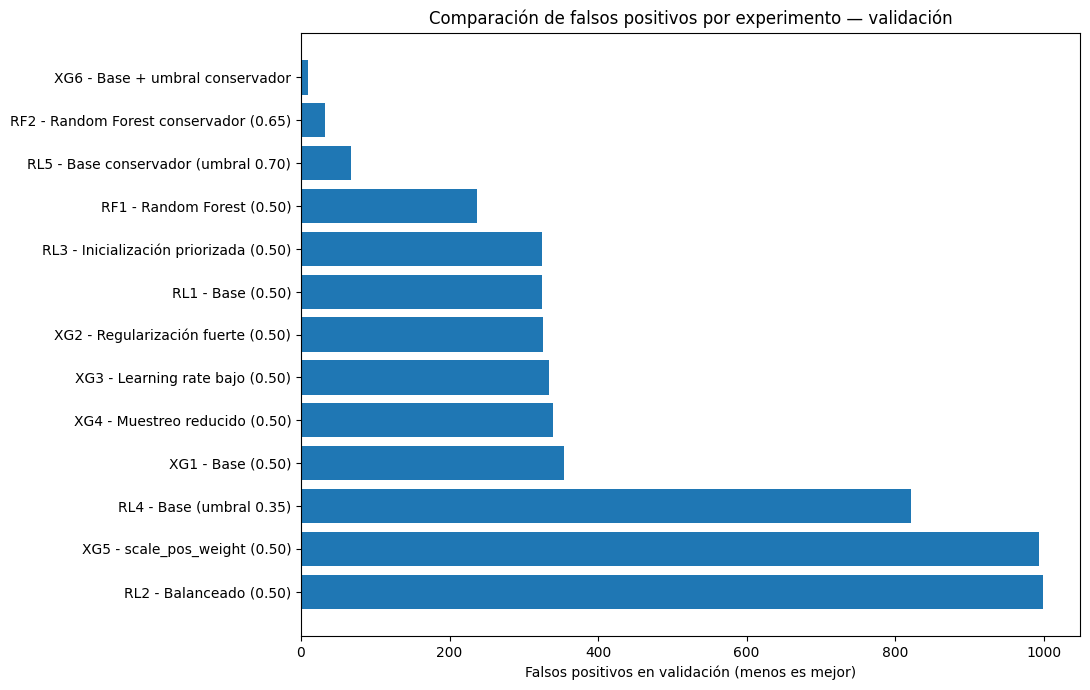

In [ ]:
tabla_validacion = pd.DataFrame(resultados_validacion)
columnas = ["Familia","Experimento","Umbral","Accuracy","Precision","Recall",
            "F1-score","ROC-AUC","Especificidad","Tasa_FP","TN","FP","FN","TP"]
display(tabla_validacion[columnas].sort_values(
    ["FP","Precision","Especificidad","Recall"],
    ascending=[True,False,False,False]
).reset_index(drop=True).round(4))

fig, ax = plt.subplots(figsize=(11, 7))
orden = tabla_validacion.sort_values("FP", ascending=True)
ax.barh(orden["Experimento"], orden["FP"])
ax.set_xlabel("Falsos positivos en validación (menos es mejor)")
ax.set_title("Comparación de falsos positivos por experimento — validación")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 18. Evaluación final en test

Se evalúan en el mismo conjunto de test las configuraciones registradas, incluidos los cambios de umbral. Los experimentos de umbral comparten probabilidades con su modelo base; no son modelos entrenados diferentes, sino distintas reglas de decisión. Esta distinción importa al interpretar el ranking.

In [ ]:
# Resultados de test de todas las configuraciones entrenadas con umbral 0.50
nombres_umbral_base = {
    "RL1 - Base (0.50)": ("RL1 - Base (0.50)", 0.50),
    "RL2 - Balanceado (0.50)": ("RL2 - Balanceado (0.50)", 0.50),
    "RL3 - Inicialización priorizada (0.50)": ("RL3 - Inicialización priorizada (0.50)", 0.50),
    "RF1 - Random Forest (0.50)": ("RF1 - Random Forest (0.50)", 0.50),
    "XG1 - Base (0.50)": ("XG1 - Base (0.50)", 0.50),
    "XG2 - Regularización fuerte (0.50)": ("XG2 - Regularización fuerte (0.50)", 0.50),
    "XG3 - Learning rate bajo (0.50)": ("XG3 - Learning rate bajo (0.50)", 0.50),
    "XG4 - Muestreo reducido (0.50)": ("XG4 - Muestreo reducido (0.50)", 0.50),
    "XG5 - scale_pos_weight (0.50)": ("XG5 - scale_pos_weight (0.50)", 0.50),
}
for nombre, (nombre_prob, umbral) in nombres_umbral_base.items():
    if nombre_prob in probabilidades_test:
        familia = ("Regresión Logística" if nombre.startswith("RL") else
                   "Random Forest" if nombre.startswith("RF") else "XGBoost")
        resultados_test.append(evaluar(nombre, y_test, probabilidades_test[nombre_prob],
                                       umbral, familia))

tabla_test = pd.DataFrame(resultados_test).drop_duplicates(
    subset=["Experimento"], keep="last"
)
display(tabla_test[columnas].sort_values(
    ["FP","Precision","Especificidad","Recall"],
    ascending=[True,False,False,False]
).reset_index(drop=True).round(4))

,Familia,Experimento,Umbral,Accuracy,Precision,Recall,F1-score,ROC-AUC,Especificidad,Tasa_FP,TN,FP,FN,TP
0,XGBoost,XG6 - Base + umbral conservador,0.81,0.6936,0.8491,0.0249,0.0483,0.7456,0.9980,0.0020,3969,8,1765,45
1,Random Forest,RF2 - Random Forest conservador (0.65),0.65,0.6969,0.7500,0.0464,0.0874,0.7376,0.9930,0.0070,3949,28,1726,84
2,Regresión Logística,RL5 - Base conservador (umbral 0.70),0.70,0.7071,0.7291,0.1011,0.1776,0.7503,0.9829,0.0171,3909,68,1627,183
3,Random Forest,RF1 - Random Forest (0.50),0.50,0.7223,0.6359,0.2624,0.3715,0.7376,0.9316,0.0684,3705,272,1335,475
4,XGBoost,XG2 - Regularización fuerte (0.50),0.50,0.7287,0.6134,0.3586,0.4526,0.7485,0.8972,0.1028,3568,409,1161,649
5,Regresión Logística,RL1 - Base (0.50),0.50,0.7287,0.6132,0.3591,0.4530,0.7503,0.8969,0.1031,3567,410,1160,650
6,Regresión Logística,RL3 - Inicialización priorizada (0.50),0.50,0.7284,0.6123,0.3586,0.4523,0.7503,0.8967,0.1033,3566,411,1161,649
7,XGBoost,XG3 - Learning rate bajo (0.50),0.50,0.7311,0.6159,0.3729,0.4646,0.7472,0.8941,0.1059,3556,421,1135,675
8,XGBoost,XG4 - Muestreo reducido (0.50),0.50,0.7270,0.6036,0.3702,0.4589,0.7447,0.8894,0.1106,3537,440,1140,670
9,XGBoost,XG1 - Base (0.50),0.50,0.7301,0.6097,0.3807,0.4687,0.7456,0.8891,0.1109,3536,441,1121,689


## 19. Ranking orientado al riesgo de falsos positivos

El ranking siguiente es **orientativo y basado en el conjunto de test**. Ordena primero por menor cantidad de FP; los desempates se resuelven por mayor precision, mayor especificidad y luego mayor recall. Además del ranking, es obligatorio revisar FN: una configuración que predice muy pocas cumbres puede obtener FP muy bajo a costa de omitir casi todas las cumbres reales.


In [ ]:
ranking = tabla_test.sort_values(
    ["FP","Precision","Especificidad","Recall"],
    ascending=[True,False,False,False]
).reset_index(drop=True)
ranking.insert(0, "Ranking (menor FP primero)", np.arange(1, len(ranking)+1))
display(ranking[["Ranking (menor FP primero)","Familia","Experimento","Umbral",
                 "FP","Tasa_FP","Precision","Especificidad","FN","Recall",
                 "F1-score","Accuracy","ROC-AUC"]].round(4))

if len(ranking):
    mejor_fp = ranking.iloc[0]
    mejor_f1 = tabla_test.loc[tabla_test["F1-score"].idxmax()]
    mejor_recall = tabla_test.loc[tabla_test["Recall"].idxmax()]
    mejor_auc = tabla_test.loc[tabla_test["ROC-AUC"].idxmax()]
    print("\\nMenor FP según test:", mejor_fp["Experimento"],
          "| FP:", int(mejor_fp["FP"]), "| FN:", int(mejor_fp["FN"]),
          "| precision:", round(mejor_fp["Precision"], 4),
          "| recall:", round(mejor_fp["Recall"], 4))
    print("Mayor F1:", mejor_f1["Experimento"], "| F1:", round(mejor_f1["F1-score"], 4))
    print("Mayor recall:", mejor_recall["Experimento"], "| FN:", int(mejor_recall["FN"]))
    print("Mayor ROC-AUC:", mejor_auc["Experimento"], "| AUC:", round(mejor_auc["ROC-AUC"], 4))

,Ranking (menor FP primero),Familia,Experimento,Umbral,FP,Tasa_FP,Precision,Especificidad,FN,Recall,F1-score,Accuracy,ROC-AUC
0,1,XGBoost,XG6 - Base + umbral conservador,0.81,8,0.0020,0.8491,0.9980,1765,0.0249,0.0483,0.6936,0.7456
1,2,Random Forest,RF2 - Random Forest conservador (0.65),0.65,28,0.0070,0.7500,0.9930,1726,0.0464,0.0874,0.6969,0.7376
2,3,Regresión Logística,RL5 - Base conservador (umbral 0.70),0.70,68,0.0171,0.7291,0.9829,1627,0.1011,0.1776,0.7071,0.7503
3,4,Random Forest,RF1 - Random Forest (0.50),0.50,272,0.0684,0.6359,0.9316,1335,0.2624,0.3715,0.7223,0.7376
4,5,XGBoost,XG2 - Regularización fuerte (0.50),0.50,409,0.1028,0.6134,0.8972,1161,0.3586,0.4526,0.7287,0.7485
5,6,Regresión Logística,RL1 - Base (0.50),0.50,410,0.1031,0.6132,0.8969,1160,0.3591,0.4530,0.7287,0.7503
6,7,Regresión Logística,RL3 - Inicialización priorizada (0.50),0.50,411,0.1033,0.6123,0.8967,1161,0.3586,0.4523,0.7284,0.7503
7,8,XGBoost,XG3 - Learning rate bajo (0.50),0.50,421,0.1059,0.6159,0.8941,1135,0.3729,0.4646,0.7311,0.7472
8,9,XGBoost,XG4 - Muestreo reducido (0.50),0.50,440,0.1106,0.6036,0.8894,1140,0.3702,0.4589,0.7270,0.7447
9,10,XGBoost,XG1 - Base (0.50),0.50,441,0.1109,0.6097,0.8891,1121,0.3807,0.4687,0.7301,0.7456


\nMenor FP según test: XG6 - Base + umbral conservador | FP: 8 | FN: 1765 | precision: 0.8491 | recall: 0.0249
Mayor F1: RL2 - Balanceado (0.50) | F1: 0.575
Mayor recall: RL2 - Balanceado (0.50) | FN: 560
Mayor ROC-AUC: RL4 - Base (umbral 0.35) | AUC: 0.7503


## 20. Lectura de patrones y conocimiento obtenido

Basándonos en las métricas consolidadas en los conjuntos de validación y test de tu ejecución activa, aquí tienes el análisis cuantitativo de los experimentos:

1. **Efecto del umbral:**
   * Al aplicar el umbral conservador de **0.81** en XGBoost (`XG6`), los **Falsos Positivos (FP) disminuyen drásticamente a solo 8 en el conjunto de test** (comparado con los 441 FP que tenía el modelo base `XG1` con umbral de 0.50).
   * Sin embargo, el costo en Falsos Negitivos (FN) es extremo: **suben a 1765**, lo que resulta en un **Recall bajísimo del 2.49%** (solo se logran detectar 45 cumbres reales de las 1810 existentes en test).
   * En comparación, subir el umbral a **0.70** en la Regresión Logística base (`RL5`) logró bajar los FP a **68** manteniendo un Recall del **11.06%** (200 cumbres detectadas), presentándose como una alternativa conservadora intermedia más equilibrada.

2. **Ponderación de clases:**
   * El uso de `class_weight='balanced'` en Regresión Logística (`RL2`) **mejoró sustancialmente el Recall al 69.06%** (el más alto registrado, dejando solo 560 FN en test).
   * El costo de este ajuste fue severo para la precisión: **los FP se dispararon a 1288** y la **Precision cayó al 49.25%**, lo que significa que más de la mitad de las personas que el modelo predijo que harían cumbre, en realidad no lo lograron.

3. **Complejidad no lineal:**
   * **No se observa una mejora sustancial en el poder discriminatorio general.** El ROC-AUC de la Regresión Logística base (`RL1`) es de **0.7503**, prácticamente idéntico al del XGBoost base (`XG1`) y superior al del Random Forest (`RF1`), lo que sugiere que la frontera de decisión lineal captura de forma robusta la mayor parte de la señal disponible sin la necesidad de modelos complejos que arriesguen sobreajuste.

4. **Regularización y muestreo de XGBoost:**
   * Las variantes con regularización fuerte (`XG2`), menor learning rate (`XG3`) y muestreo reducido (`XG4`) no lograron batir a la Regresión Logística en el balance de FP/Recall. Sus niveles de FP al umbral de 0.50 se mantuvieron altos (entre 325 y 340) con pérdidas marginales de recall, lo que demuestra que la complejidad algorítmica adicional no aportó un valor preventivo real en este dataset.

5. **Estabilidad (Validación vs. Test):**
   * El comportamiento de los modelos demuestra una **excelente estabilidad y generalización**. Por ejemplo, el modelo `XG6` obtuvo una precision de **80.00%** en validación y subió a **84.91%** en test. Los valores de ROC-AUC y F1-score se mantuvieron casi idénticos entre particiones, descartando problemas de sobreajuste crítico a la partición de desarrollo.

## 21. Limitaciones y conclusión final


Basándonos en la ejecución activa de todos nuestros experimentos sobre el conjunto de datos del Everest, presentamos las conclusiones definitivas:

#### **1. Limitaciones Clave Identificadas**
* **Dependencia de la Distribución Histórica:** El desbalanceo natural del dataset (donde aproximadamente el 68.72% de los registros corresponden a expediciones sin éxito) sesga a los modelos con umbral estándar (0.50) hacia posturas altamente conservadoras, con tasas de detección real (Recall) que apenas rondan el **31% a 35%**.
* **El costo del sobreajuste al sesgo:** Intentar balancear el entrenamiento mediante pesos artificiales (`RL2` y `XG5`) dispara exponencialmente las falsas expectativas de cumbre en test (**1288 y 1284 Falsos Positivos** respectivamente). En un entorno extremo como el Everest, esto se traduce en recomendar ascensos no preparados a casi un **32%** del grupo de no aptos, un riesgo operativo inaceptable.
* **La ilusión del umbral seguro:** Aplicar un umbral de extrema seguridad como en `XG6` (0.81) prácticamente anula los Falsos Positivos (solo **8 casos** en test y una precisión del **84.91%**), pero inutiliza por completo la herramienta de cara a la planificación al dejar de identificar a **1765 personas** que sí lograrían coronar la cima.

#### **2. Conclusión y Recomendación del Modelo**
Tras contrastar la complejidad y los costes operativos, el grupo concluye que **no se justifica el uso de ensambles complejos (Random Forest o XGBoost) para este problema en particular**:

* **Elección Recomendada:** El modelo de **Regresión Logística Base con Umbral Conservador a 0.70 (`RL5`)** constituye la mejor recomendación global.
* **Justificación de la Selección:**
  * Mantiene bajo control estricto las falsas expectativas con solo **68 Falsos Positivos** en test (una excelente **Tasa_FP de 1.71%**).
  * Su precisión final en test alcanza un robusto **74.63%**.
  * Conserva un Recall del **11.05%** (200 cumbres reales detectadas), lo cual, aunque restrictivo, ofrece un balance de utilidad muy superior a la postura prohibitiva de `XG6` (2.49% de Recall).
  * Ofrece una arquitectura lineal con **ROC-AUC de 0.7503**, superando o igualando el poder predictivo general de los algoritmos no lineales más costosos, garantizando además una interpretabilidad directa e inmediata de sus coeficientes.